# Precio de autos usados: análisis exploratorio

**TC5061 · Operaciones de aprendizaje automático (MLOps)**

- **Alumno:** Roberto Nájera Lizárraga
- **Dataset:** *Vehicle dataset* de CarDekho, archivo `data/raw/car_details_v3.csv` ([Kaggle](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho))

**Objetivo.** Explorar el dataset y justificar las decisiones de limpieza. El problema es de **regresión**: estimar el precio de venta de un auto usado (`selling_price`) a partir de sus características.

**Contenido.** 1) Carga y descripción · 2) Análisis exploratorio · 3) Limpieza

**Alcance.** Este notebook es solo de exploración. La limpieza, el entrenamiento, la evaluación y el registro en MLflow viven en el paquete `semana_3_refactored_code` y se ejecutan desde la línea de comandos (ver `README.md`).

**Para reproducirlo.** Ejecuta todas las celdas en orden desde la carpeta `notebooks/`.


In [1]:
# --- Análisis y visualización ---
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from loguru import logger

# Funciones y constantes del paquete: se importan para no mantener dos copias
logger.disable("semana_3_refactored_code")  # sin los mensajes de avance del paquete
from semana_3_refactored_code.dataset import (
    COLS_FICHA, KM_MAXIMO, KM_MINIMO, RUTA_CRUDOS, a_numero, limpiar_datos,
)
from semana_3_refactored_code.plots import COLOR, formato_miles

# Opciones de presentación de tablas y gráficas
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

print(f"pandas {pd.__version__} | seaborn {sns.__version__}")


pandas 3.0.5 | seaborn 0.13.2


## Paso 1. Carga y descripción del dataset

In [2]:
# Carga del archivo original. df_raw no se modifica: la limpieza se hace sobre una copia
df_raw = pd.read_csv(RUTA_CRUDOS)
print(f"Registros: {df_raw.shape[0]:,} | Variables: {df_raw.shape[1]}")
df_raw.head()

Registros: 8,128 | Variables: 13


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.00
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.00
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.00
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.00
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.00


In [3]:
# Tipo de dato y cantidad de valores no nulos de cada columna
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 1.6 MB


**Estructura.** El archivo tiene **8,128 registros** y **13 variables**. Cada fila describe un auto usado puesto en venta: 1 variable es el objetivo y 12 son descriptivas.

| Variable | Tipo al leerla | Significado | Rol |
|---|---|---|---|
| `name` | texto | Marca, modelo y versión del auto | descriptiva |
| `year` | entero | Año del auto | descriptiva |
| `selling_price` | entero | Precio de venta | **objetivo** |
| `km_driven` | entero | Kilómetros recorridos | descriptiva |
| `fuel` | texto | Combustible (Diesel, Petrol, CNG, LPG) | descriptiva |
| `seller_type` | texto | Tipo de vendedor (Individual, Dealer, Trustmark Dealer) | descriptiva |
| `transmission` | texto | Transmisión (Manual, Automatic) | descriptiva |
| `owner` | texto | Historial de dueños (First Owner, Second Owner, ...) | descriptiva |
| `mileage` | texto | Rendimiento de combustible, con unidad (`kmpl` o `km/kg`) | descriptiva |
| `engine` | texto | Cilindrada del motor, con unidad (`CC`) | descriptiva |
| `max_power` | texto | Potencia máxima, con unidad (`bhp`) | descriptiva |
| `torque` | texto | Par motor, en texto libre | descriptiva |
| `seats` | decimal | Número de asientos | descriptiva |

**Notas.**
- El archivo no trae diccionario de datos: el significado se toma del nombre de cada columna y de las unidades que aparecen en los valores.
- **Supuesto:** `selling_price` está en rupias indias (INR), porque CarDekho es un portal de India.
- Desde aquí se ven tres cosas por corregir: `mileage`, `engine` y `max_power` son medidas guardadas como texto, `seats` es un conteo guardado como decimal, y cinco columnas tienen menos valores no nulos que el total de filas.

## Paso 2. Análisis exploratorio (EDA)

El EDA se hace sobre los datos **tal como llegan**, porque parte de su función es encontrar los problemas de calidad que se corrigen en el Paso 3. Las relaciones con `mileage`, `engine` y `max_power` se revisan al final del Paso 3, cuando ya son numéricas.

### 2.1 Estadísticas descriptivas

In [4]:
# Variables numéricas
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
year,"8,128.00","2,013.80",4.04,"1,983.00","2,011.00","2,015.00","2,017.00","2,020.00"
selling_price,"8,128.00","638,271.81","806,253.40","29,999.00","254,999.00","450,000.00","675,000.00","10,000,000.00"
km_driven,"8,128.00","69,819.51","56,550.55",1.00,"35,000.00","60,000.00","98,000.00","2,360,457.00"
seats,"7,907.00",5.42,0.96,2.00,5.00,5.00,5.00,14.00


In [5]:
# Variables de texto: cuántos valores distintos hay y cuál es el más frecuente
cols_texto = ["name", "fuel", "seller_type", "transmission", "owner", "mileage", "engine", "max_power", "torque"]
df_raw[cols_texto].describe().T

,count,unique,top,freq
name,8128,2058,Maruti Swift Dzire VDI,129
fuel,8128,4,Diesel,4402
seller_type,8128,3,Individual,6766
transmission,8128,2,Manual,7078
owner,8128,5,First Owner,5289
mileage,7907,393,18.9 kmpl,225
engine,7907,121,1248 CC,1017
max_power,7913,322,74 bhp,377
torque,7906,441,190Nm@ 2000rpm,530


**Lectura.**
- **Precio:** la media (₹638 mil) queda muy por encima de la mediana (₹450 mil) y el máximo llega a ₹10 millones. Es una distribución con cola larga hacia los precios altos.
- **Kilometraje:** la mediana es de 60,000 km, pero el máximo es de 2,360,457 km y el mínimo de 1 km. Los dos extremos son sospechosos y se revisan en la limpieza.
- **Año:** va de 1983 a 2020 y la mitad de los autos es de 2015 o posterior.
- **Asientos:** solo hay 7,907 valores de 8,128, es decir, hay faltantes.
- **Texto:** `name` tiene 2,058 valores distintos, demasiados para usarla tal cual. Predominan el diésel (4,402 autos), el vendedor particular (6,766), la transmisión manual (7,078) y el primer dueño (5,289).

### 2.2 Variable objetivo: `selling_price`

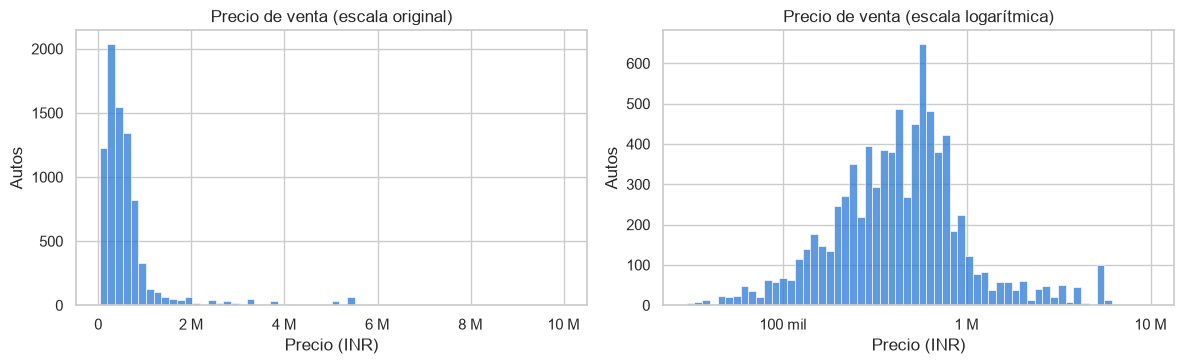

Asimetría del precio:      4.19
Asimetría de log(precio):  0.22
Autos con precio menor a 1 millón: 89.3%


In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))

# Escala original: casi todos los autos quedan amontonados a la izquierda
sns.histplot(df_raw["selling_price"], bins=60, color=COLOR, ax=ejes[0])
ejes[0].xaxis.set_major_formatter(FuncFormatter(formato_miles))
ejes[0].set(title="Precio de venta (escala original)", xlabel="Precio (INR)", ylabel="Autos")

# Escala logarítmica: la misma variable se ve casi simétrica
sns.histplot(df_raw["selling_price"], bins=60, log_scale=True, color=COLOR, ax=ejes[1])
ejes[1].xaxis.set_major_formatter(FuncFormatter(formato_miles))
ejes[1].set(title="Precio de venta (escala logarítmica)", xlabel="Precio (INR)", ylabel="Autos")

plt.tight_layout()
plt.show()

# La asimetría (skew) mide qué tan cargada está la distribución hacia un lado; 0 es simétrica
print(f"Asimetría del precio:      {df_raw['selling_price'].skew():.2f}")
print(f"Asimetría de log(precio):  {np.log(df_raw['selling_price']).skew():.2f}")
print(f"Autos con precio menor a 1 millón: {(df_raw['selling_price'] < 1_000_000).mean():.1%}")

**Lectura.** El 89 % de los autos cuesta menos de ₹1 millón, pero unos pocos autos de lujo estiran la escala hasta ₹10 millones (asimetría de 4.19). En escala logarítmica la asimetría baja a 0.22. Esto adelanta una decisión del Paso 4: conviene modelar el **logaritmo del precio**, para que los autos caros no dominen el ajuste de un modelo lineal.

### 2.3 Variables numéricas

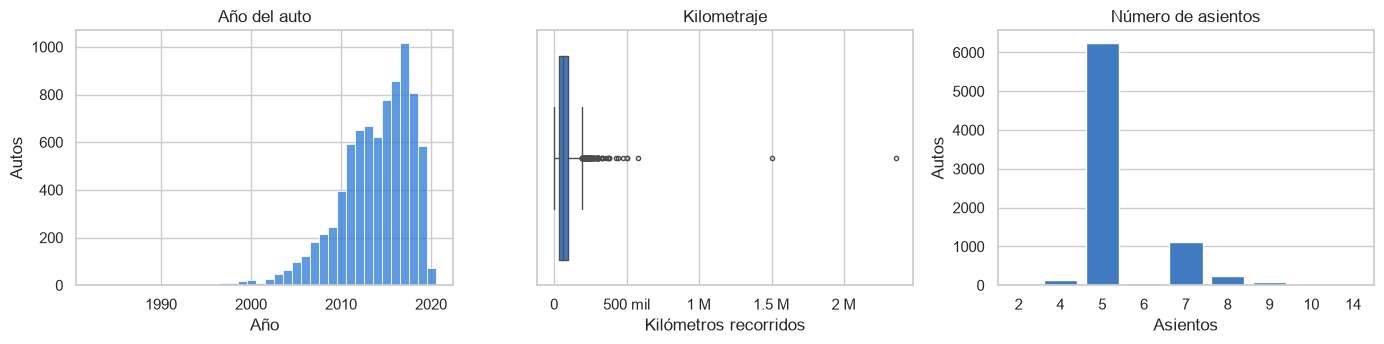

Autos de 2010 a 2019: 86%
Autos con 5 asientos, entre los que tienen el dato: 79%


In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.6))

# Año: una barra por año
sns.histplot(df_raw["year"], discrete=True, color=COLOR, ax=ejes[0])
ejes[0].set(title="Año del auto", xlabel="Año", ylabel="Autos")

# Kilometraje: el diagrama de caja deja ver los valores extremos
sns.boxplot(x=df_raw["km_driven"], color=COLOR, fliersize=3, ax=ejes[1])
ejes[1].xaxis.set_major_formatter(FuncFormatter(formato_miles))
ejes[1].set(title="Kilometraje", xlabel="Kilómetros recorridos")

# Asientos: es un conteo, así que se grafica la frecuencia de cada valor
sns.countplot(x=df_raw["seats"].dropna().astype(int), color=COLOR, ax=ejes[2])
ejes[2].set(title="Número de asientos", xlabel="Asientos", ylabel="Autos")

plt.tight_layout()
plt.show()

print(f"Autos de 2010 a 2019: {df_raw['year'].between(2010, 2019).mean():.0%}")
print(f"Autos con 5 asientos, entre los que tienen el dato: {(df_raw['seats'].dropna() == 5).mean():.0%}")

**Lectura.**
- **Año:** el 86 % de los autos es de 2010 a 2019. Los anteriores a 2005 son pocos.
- **Kilometraje:** la caja queda aplastada contra el cero por dos puntos aislados arriba de 1 millón de km. No parecen kilometrajes reales y se revisan en la sección de outliers.
- **Asientos:** el 79 % de los autos con dato tiene 5 asientos y le siguen los de 7. Los de 8 o más son pocos.

### 2.4 Variables categóricas y su relación con el precio

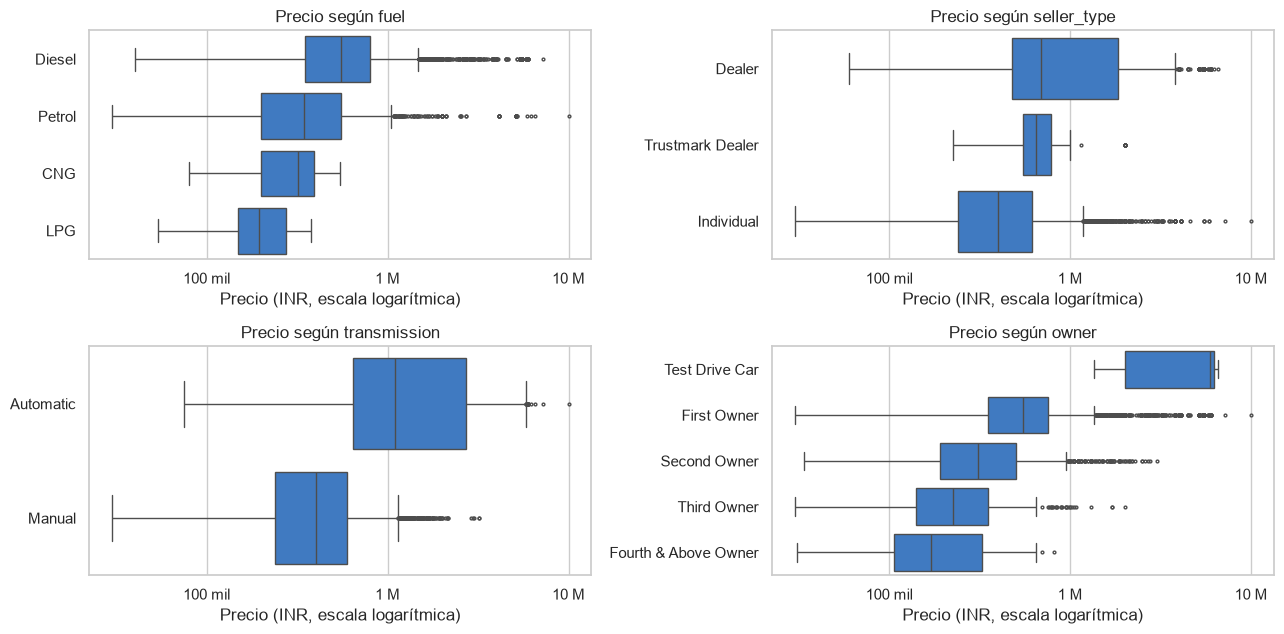

In [8]:
cols_cat = ["fuel", "seller_type", "transmission", "owner"]

fig, ejes = plt.subplots(2, 2, figsize=(13, 6.5))
for eje, col in zip(ejes.ravel(), cols_cat):
    # Categorías ordenadas de mayor a menor precio mediano
    orden = df_raw.groupby(col)["selling_price"].median().sort_values(ascending=False).index
    sns.boxplot(data=df_raw, x="selling_price", y=col, order=orden, color=COLOR, fliersize=2, ax=eje)
    eje.set_xscale("log")   # escala logarítmica para comparar cajas con precios muy distintos
    eje.xaxis.set_major_formatter(FuncFormatter(formato_miles))
    eje.set(title=f"Precio según {col}", xlabel="Precio (INR, escala logarítmica)", ylabel="")

plt.tight_layout()
plt.show()

In [9]:
# Número de autos y precio mediano de cada categoría
resumen_cat = pd.concat({
    col: (df_raw.groupby(col)["selling_price"]
          .agg(autos="count", precio_mediano="median")
          .sort_values("precio_mediano", ascending=False))
    for col in cols_cat
})
resumen_cat

autos  precio_mediano
fuel         Diesel                 4402      550,000.00
             Petrol                 3631      345,000.00
             CNG                      57      320,000.00
             LPG                      38      195,500.00
seller_type  Dealer                 1126      690,000.00
             Trustmark Dealer        236      650,000.00
             Individual             6766      400,000.00
transmission Automatic              1050    1,100,000.00
             Manual                 7078      400,000.00
owner        Test Drive Car            5    5,923,000.00
             First Owner            5289      550,000.00
             Second Owner           2105      310,000.00
             Third Owner             555      225,000.00
             Fourth & Above Owner    174      170,000.00

**Lectura.**
- **Transmisión:** es la diferencia más grande. El precio mediano de los automáticos (₹1.1 millones) es casi el triple que el de los manuales (₹400 mil).
- **Combustible:** el diésel (₹550 mil) vale más que la gasolina (₹345 mil). CNG y LPG son muy pocos (57 y 38 autos); el LPG es el más barato, con menos de ₹200 mil.
- **Vendedor:** las agencias (₹690 mil y ₹650 mil) venden más caro que los particulares (₹400 mil).
- **Dueños:** el precio baja con cada dueño: ₹550 mil, ₹310 mil, ₹225 mil y ₹170 mil. *Test Drive Car* es una categoría de solo 5 autos, casi nuevos y muy caros.

Son diferencias de una variable a la vez, no efectos aislados: por ejemplo, los automáticos también suelen ser más nuevos y potentes.

### 2.5 Diagnóstico de calidad de los datos

In [10]:
# Valores faltantes por columna
faltantes = df_raw.isna().sum()
faltantes = faltantes[faltantes > 0]
print(pd.DataFrame({"faltantes": faltantes, "% de filas": (faltantes / len(df_raw) * 100).round(1)}))

# Filas duplicadas exactas (iguales en las 13 columnas)
n_dup = df_raw.duplicated().sum()
print(f"\nFilas duplicadas exactas: {n_dup:,} ({n_dup / len(df_raw):.1%})")

# Columnas numéricas guardadas como texto
print("\nEjemplos de valores guardados como texto:")
print(df_raw[["mileage", "engine", "max_power", "torque"]].head(4).to_string(index=False))

           faltantes  % de filas
mileage          221        2.70
engine           221        2.70
max_power        215        2.60
torque           222        2.70
seats            221        2.70

Filas duplicadas exactas: 1,202 (14.8%)

Ejemplos de valores guardados como texto:
   mileage  engine  max_power                   torque
 23.4 kmpl 1248 CC     74 bhp           190Nm@ 2000rpm
21.14 kmpl 1498 CC 103.52 bhp      250Nm@ 1500-2500rpm
 17.7 kmpl 1497 CC     78 bhp    12.7@ 2,700(kgm@ rpm)
 23.0 kmpl 1396 CC     90 bhp 22.4 kgm at 1750-2750rpm


**Hallazgos que pasan a la limpieza.**
1. **Faltantes:** cinco columnas tienen entre 215 y 222 valores faltantes (cerca del 2.7 % de las filas).
2. **Duplicados:** 1,202 filas (14.8 %) son copias exactas de otra.
3. **Tipos incorrectos:** `mileage`, `engine` y `max_power` son números guardados como texto con su unidad, `torque` es texto libre y `seats` es decimal.
4. **Valores extremos:** kilometrajes de 1 km y de más de 2 millones de km, y precios de hasta ₹10 millones.
5. **Alta cardinalidad:** `name` tiene 2,058 valores distintos.

## Paso 3. Limpieza de datos

El orden importa. Primero se quitan los duplicados, porque se evalúan sobre las filas originales. Después se corrigen los tipos, porque sin números no se pueden ver los faltantes ocultos ni los outliers. Luego se tratan los faltantes y al final los outliers. Cada decisión se anota en una bitácora con el número de filas que queda.

### 3.1 Duplicados

In [11]:
df = df_raw.copy()
bitacora = [("Datos originales", len(df))]   # filas que quedan después de cada decisión

n_dup = df.duplicated().sum()
print(f"Filas duplicadas exactas: {n_dup:,} ({n_dup / len(df):.1%})")

# Ejemplo: mismo auto, mismo precio y mismo kilometraje, repetido
df[df.duplicated(keep=False)].sort_values(["name", "year", "selling_price", "km_driven"]).head(4)

Filas duplicadas exactas: 1,202 (14.8%)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1977,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.00
7324,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.00
2129,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.00
7775,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.00


In [12]:
# ¿En qué tipo de vendedor se concentran los duplicados?
dup_por_vendedor = pd.DataFrame({
    "filas": df["seller_type"].value_counts(),
    "duplicadas": df.loc[df.duplicated(), "seller_type"].value_counts(),
})
dup_por_vendedor["% duplicadas"] = dup_por_vendedor["duplicadas"] / dup_por_vendedor["filas"] * 100
dup_por_vendedor

,filas,duplicadas,% duplicadas
seller_type,,,
Individual,6766,548,8.10
Dealer,1126,445,39.52
Trustmark Dealer,236,209,88.56


In [13]:
# Decisión 1: se conserva la primera aparición de cada fila
df = df.drop_duplicates().reset_index(drop=True)
bitacora.append(("Sin duplicados exactos", len(df)))
print(f"Filas después de quitar duplicados: {len(df):,}")

Filas después de quitar duplicados: 6,926


**Decisión 1: eliminar los 1,202 duplicados exactos y conservar la primera aparición.**
- El dataset no tiene un identificador de anuncio. Las filas repetidas coinciden en las 13 columnas, incluidos el precio y el kilometraje exactos. **Supuesto:** son el mismo anuncio capturado más de una vez, no autos distintos.
- La repetición se concentra en las agencias: son copias el 88.6 % de las filas de *Trustmark Dealer* y el 39.5 % de las de *Dealer*, frente al 8.1 % de las de particulares.
- Si se dejaran, la misma fila podría caer en entrenamiento y en prueba. El modelo se evaluaría con autos que ya vio y la métrica saldría mejor de lo que es (fuga de información).

### 3.2 Tipos incorrectos

In [14]:
# Las tres columnas guardan "número + unidad" como texto. ¿Qué unidades aparecen?
for col in ["mileage", "engine", "max_power"]:
    unidades = df[col].str.split().str[-1].value_counts().to_dict()
    print(f"{col:10s} -> {unidades}")

# La unidad de mileage depende del combustible
pd.crosstab(df["fuel"], df["mileage"].str.split().str[-1].rename("unidad de mileage"))

mileage    -> {'kmpl': 6631, 'km/kg': 87}
engine     -> {'CC': 6718}
max_power  -> {'bhp': 6718, '0': 3}


unidad de mileage,km/kg,kmpl
fuel,,
CNG,52,0
Diesel,0,3658
LPG,35,0
Petrol,0,2973


In [15]:
# Decisión 2 (a_numero viene de dataset.py): convertir a número y contar cuántos textos no se pudieron convertir
for col in ["mileage", "engine", "max_power"]:
    no_nulos_antes = df[col].notna().sum()
    df[col] = a_numero(df[col])
    perdidos = no_nulos_antes - df[col].notna().sum()
    print(f"{col:10s}: {perdidos} valor(es) con texto no convertible, ahora NaN")

df[["mileage", "engine", "max_power"]].dtypes

mileage   : 0 valor(es) con texto no convertible, ahora NaN
engine    : 0 valor(es) con texto no convertible, ahora NaN
max_power : 1 valor(es) con texto no convertible, ahora NaN


mileage      float64
engine       float64
max_power    float64
dtype: object

In [16]:
# torque: texto libre con varios formatos y dos unidades (Nm y kgm)
print("Valores distintos en torque:", df["torque"].nunique())
print(df["torque"].head(6).tolist())

# Decisión 3: se descarta la columna para el modelo base
df = df.drop(columns="torque")

Valores distintos en torque: 441
['190Nm@ 2000rpm', '250Nm@ 1500-2500rpm', '12.7@ 2,700(kgm@ rpm)', '22.4 kgm at 1750-2750rpm', '11.5@ 4,500(kgm@ rpm)', '113.75nm@ 4000rpm']


**Decisión 2: convertir `mileage`, `engine` y `max_power` a número**, quitando la unidad.
- Uso `errors="coerce"` y cuento cuántos valores se pierden, para que la conversión no esconda problemas. Solo se pierde 1 valor de `max_power`, que traía la unidad sin número.
- `mileage` mezcla dos unidades: `kmpl` en los autos de gasolina y diésel, y `km/kg` en los 87 autos de gas (CNG y LPG) que traen el dato. **No convierto una unidad en la otra**, porque habría que suponer la densidad del gas. La tabla muestra que la unidad depende por completo de `fuel`, así que el modelo puede distinguir a esos autos con esa variable. Queda como limitación: el número no es comparable entre los dos grupos.

**Decisión 3: descartar `torque`.** Es texto libre con 441 formas distintas y dos unidades (`Nm` y `kgm`). Extraerlo bien pide reglas propias para cada formato, y para un modelo base el motor ya está descrito por `engine` y `max_power`. Queda como mejora posible.

`seats` se convierte a entero en la siguiente sección, cuando ya no tiene faltantes.

### 3.3 Valores faltantes

In [17]:
# Faltantes ocultos: un auto no puede rendir 0 km por litro ni tener 0 bhp de potencia
print("mileage igual a 0:  ", (df["mileage"] == 0).sum())
print("max_power igual a 0:", (df["max_power"] == 0).sum())
df["mileage"] = df["mileage"].replace(0, np.nan)
df["max_power"] = df["max_power"].replace(0, np.nan)

# ¿Los faltantes aparecen juntos o por separado?
patron = df[COLS_FICHA].isna().value_counts().rename("filas").reset_index()
patron

mileage igual a 0:   15
max_power igual a 0: 3


,mileage,engine,max_power,seats,filas
0,False,False,False,False,6702
1,True,True,True,True,208
2,True,False,False,False,15
3,False,False,True,False,1


In [18]:
# Filas a las que les falta toda la ficha técnica
sin_ficha = df[COLS_FICHA].isna().all(axis=1)
print(f"Filas sin ficha técnica: {sin_ficha.sum()} ({sin_ficha.mean():.1%})")

# ¿Se parecen al resto? Mediana de año y de precio de cada grupo
comparacion = df.groupby(sin_ficha)[["year", "selling_price"]].median()
comparacion.index = ["con ficha técnica", "sin ficha técnica"]
comparacion

Filas sin ficha técnica: 208 (3.0%)


,year,selling_price
con ficha técnica,"2,014.00","420,000.00"
sin ficha técnica,"2,008.00","175,000.00"


In [19]:
# Decisión 4: se eliminan las filas sin ficha técnica
df = df[~sin_ficha].reset_index(drop=True)
df["seats"] = df["seats"].astype(int)   # ya sin faltantes, los asientos son un entero
bitacora.append(("Sin filas sin ficha técnica", len(df)))

# Decisión 5: los faltantes aislados se quedan y se imputan dentro del pipeline (Paso 4)
print("Faltantes que quedan por columna:")
print(df.isna().sum()[df.isna().sum() > 0])

Faltantes que quedan por columna:
mileage      15
max_power     1
dtype: int64


**Faltantes ocultos.** 15 autos tienen `mileage` igual a 0 y 3 tienen `max_power` igual a 0. Son valores físicamente imposibles, así que los trato como faltantes.

**Decisión 4: eliminar las 208 filas sin ficha técnica (3.0 %).**
- A esas filas les faltan **a la vez** `mileage`, `engine`, `max_power` y `seats`. Imputarlas sería inventar 4 de las 6 variables numéricas del mismo auto.
- Costo de la decisión: esas filas son de autos más antiguos y baratos (año mediano 2008 y precio mediano ₹175 mil, frente a 2014 y ₹420 mil). Al quitarlas, el modelo queda con menos ejemplos de autos viejos.

**Decisión 5: conservar e imputar los 16 faltantes aislados** (15 en `mileage` y 1 en `max_power`).
- A estos autos solo les falta un dato, así que vale la pena conservarlos.
- Se imputan con la **mediana**, y la imputación va **dentro del pipeline** del Paso 4. Así la mediana se calcula solo con los datos de entrenamiento y no se filtra información del conjunto de prueba.

### 3.4 Outliers

In [20]:
# Regla de 1.5 × IQR en cada variable numérica
numericas = ["selling_price", "km_driven", "year", "mileage", "engine", "max_power", "seats"]
filas_iqr = []
for col in numericas:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    fuera = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    filas_iqr.append({"variable": col, "mínimo": df[col].min(), "máximo": df[col].max(),
                      "fuera de 1.5×IQR": fuera, "% de filas": fuera / len(df) * 100})
pd.DataFrame(filas_iqr).set_index("variable")

,mínimo,máximo,fuera de 1.5×IQR,% de filas
variable,,,,
selling_price,"29,999.00","10,000,000.00",306,4.55
km_driven,1.00,"2,360,457.00",161,2.40
year,"1,994.00","2,020.00",57,0.85
mileage,9.00,42.00,6,0.09
engine,624.00,"3,604.00",1207,17.97
max_power,32.80,400.00,304,4.53
seats,2.00,14.00,1464,21.79


In [21]:
# Revisión de los extremos, registro por registro
cols_ver = ["name", "year", "km_driven", "owner", "selling_price"]
print("Kilometrajes más altos y más bajos:")
display(pd.concat([df.nlargest(4, "km_driven"), df.nsmallest(2, "km_driven")])[cols_ver])
print("Precios más altos:")
display(df.nlargest(3, "selling_price")[cols_ver])

Kilometrajes más altos y más bajos:


,name,year,km_driven,owner,selling_price
3055,Hyundai i20 Asta 1.2,2007,2360457,Second Owner,550000
1595,Mahindra XUV500 W6 2WD,2012,1500000,First Owner,500000
3077,Maruti Wagon R LXI Minor,2010,577414,Second Owner,194000
3174,Maruti Wagon R VXI BS IV,2011,500000,Second Owner,229999
6533,Maruti Eeco 5 STR With AC Plus HTR CNG,2011,1,Fourth & Above Owner,209000
379,Honda City i-VTEC CVT V,2018,1000,First Owner,1085000


Precios más altos:


,name,year,km_driven,owner,selling_price
164,Volvo XC90 T8 Excellence BSIV,2017,30000,First Owner,10000000
2600,BMW X7 xDrive 30d DPE,2020,5000,First Owner,7200000
4157,Audi A6 35 TFSI Matrix,2019,23600,Test Drive Car,6523000


In [22]:
# Decisión 6: se eliminan solo los kilometrajes inverosímiles
km_valido = df["km_driven"].between(KM_MINIMO, KM_MAXIMO)
print(f"Filas con kilometraje fuera de [{KM_MINIMO:,}, {KM_MAXIMO:,}]:", (~km_valido).sum())
df = df[km_valido].reset_index(drop=True)
bitacora.append(("Sin kilometrajes inverosímiles", len(df)))

Filas con kilometraje fuera de [100, 1,000,000]: 3


**La regla de IQR no sirve para borrar a ciegas.** Marca 306 precios (4.6 %), 1,207 cilindradas (18.0 %) y 1,464 valores de asientos (21.8 %). En `seats` el motivo es que el rango intercuartil vale cero: todo auto que no tiene 5 asientos queda marcado. Casi todos esos casos son autos reales (de lujo, con mucho uso o de 7 asientos) que el modelo debe aprender a valuar. Por eso separo **valor atípico** de **valor erróneo**.

**Decisión 6: eliminar solo los kilometrajes inverosímiles (3 filas).** La regla es conservar `km_driven` entre 100 y 1,000,000.
- 2,360,457 km en un auto de 2007 y 1,500,000 km en uno de 2012 equivalen a más de 180,000 km por año, tomando 2020 (el año más reciente del dataset) como referencia.
- 1 km en un auto de 2011 que va en su cuarto dueño o más es una contradicción.
- Los autos de hasta 577,414 km se conservan: son altos, pero posibles.

**Decisión 7: conservar los precios altos y los asientos poco comunes.** El auto más caro (un Volvo XC90 de ₹10 millones) y los que le siguen son modelos de lujo, con precios creíbles para ese segmento. El de 14 asientos es una camioneta de pasajeros y los de 2 son pick-ups. La asimetría del precio no se resuelve borrando filas, sino modelando su logaritmo (Paso 4).

### 3.5 Variable `name`: de 1,982 valores a la marca

In [23]:
print("Valores distintos en name:", df["name"].nunique())

# Decisión 8: la marca es la primera palabra del nombre; se corrigen las dos marcas de dos palabras
df["brand"] = df["name"].str.split().str[0].replace({"Land": "Land Rover", "Ashok": "Ashok Leyland"})
df = df.drop(columns="name")

print("Marcas distintas:", df["brand"].nunique())
df["brand"].value_counts().head(6)

Valores distintos en name: 1982
Marcas distintas: 31


brand
Maruti      2089
Hyundai     1213
Mahindra     708
Tata         633
Honda        361
Ford         353
Name: count, dtype: int64

**Decisión 8: reemplazar `name` por la marca (`brand`).** Con 1,982 valores distintos en 6,715 filas, `name` casi identifica a cada versión de auto y no sirve como variable categórica. La marca resume la parte más útil en 31 categorías.

### 3.6 Resultado de la limpieza

In [24]:
# Bitácora: filas que quedan después de cada decisión
resumen_limpieza = pd.DataFrame(bitacora, columns=["Paso", "Filas"])
resumen_limpieza["Filas eliminadas"] = (resumen_limpieza["Filas"].shift(1) - resumen_limpieza["Filas"]).fillna(0).astype(int)
display(resumen_limpieza)
print(f"Se conserva el {len(df) / len(df_raw):.1%} de las filas originales.\n")

# Estructura final: tipos correctos y solo los 16 faltantes aislados
df.info()

,Paso,Filas,Filas eliminadas
0,Datos originales,8128,0
1,Sin duplicados exactos,6926,1202
2,Sin filas sin ficha técnica,6718,208
3,Sin kilometrajes inverosímiles,6715,3


Se conserva el 82.6% de las filas originales.

<class 'pandas.DataFrame'>
RangeIndex: 6715 entries, 0 to 6714
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           6715 non-null   int64  
 1   selling_price  6715 non-null   int64  
 2   km_driven      6715 non-null   int64  
 3   fuel           6715 non-null   str    
 4   seller_type    6715 non-null   str    
 5   transmission   6715 non-null   str    
 6   owner          6715 non-null   str    
 7   mileage        6700 non-null   float64
 8   engine         6715 non-null   float64
 9   max_power      6714 non-null   float64
 10  seats          6715 non-null   int64  
 11  brand          6715 non-null   object 
dtypes: float64(3), int64(4), object(1), str(4)
memory usage: 851.5+ KB


In [25]:
# El paquete aplica las mismas decisiones: limpiar_datos() debe dar exactamente este df
pd.testing.assert_frame_equal(limpiar_datos(df_raw), df)
print("dataset.limpiar_datos() reproduce la limpieza de este notebook")

dataset.limpiar_datos() reproduce la limpieza de este notebook

**Resumen de decisiones.**

| # | Problema | Evidencia | Decisión | Motivo |
|---|---|---|---|---|
| 1 | Duplicados | 1,202 filas idénticas en las 13 columnas | Eliminar y conservar la primera | Evitar fuga entre entrenamiento y prueba |
| 2 | Tipos incorrectos | `mileage`, `engine` y `max_power` como texto con unidad | Convertir a número | Sin números no se pueden analizar ni modelar |
| 3 | Texto libre | `torque` con 441 formatos y dos unidades | Descartar la columna | Costo alto de extracción para un modelo base |
| 4 | Faltantes en bloque | 208 filas sin `mileage`, `engine`, `max_power` ni `seats` | Eliminar las filas | Imputar sería inventar 4 variables por auto |
| 5 | Faltantes aislados | 15 en `mileage` (venían como 0) y 1 en `max_power` | Imputar con la mediana dentro del pipeline | Conservar el auto sin filtrar datos de prueba |
| 6 | Outliers erróneos | 3 kilometrajes fuera de 100 a 1,000,000 km | Eliminar las filas | Valores físicamente inverosímiles |
| 7 | Outliers reales | Precios de lujo, 7 o más asientos | Conservar | Son autos reales; el sesgo se trata con logaritmo |
| 8 | Alta cardinalidad | `name` con 1,982 valores distintos | Extraer la marca (31 categorías) | Volverla una variable categórica utilizable |

Quedan **6,715 filas y 12 columnas** (el 82.6 % de las filas originales).

### 3.7 Relaciones entre variables, con los datos limpios

Con `mileage`, `engine` y `max_power` ya numéricas se completa el análisis exploratorio.

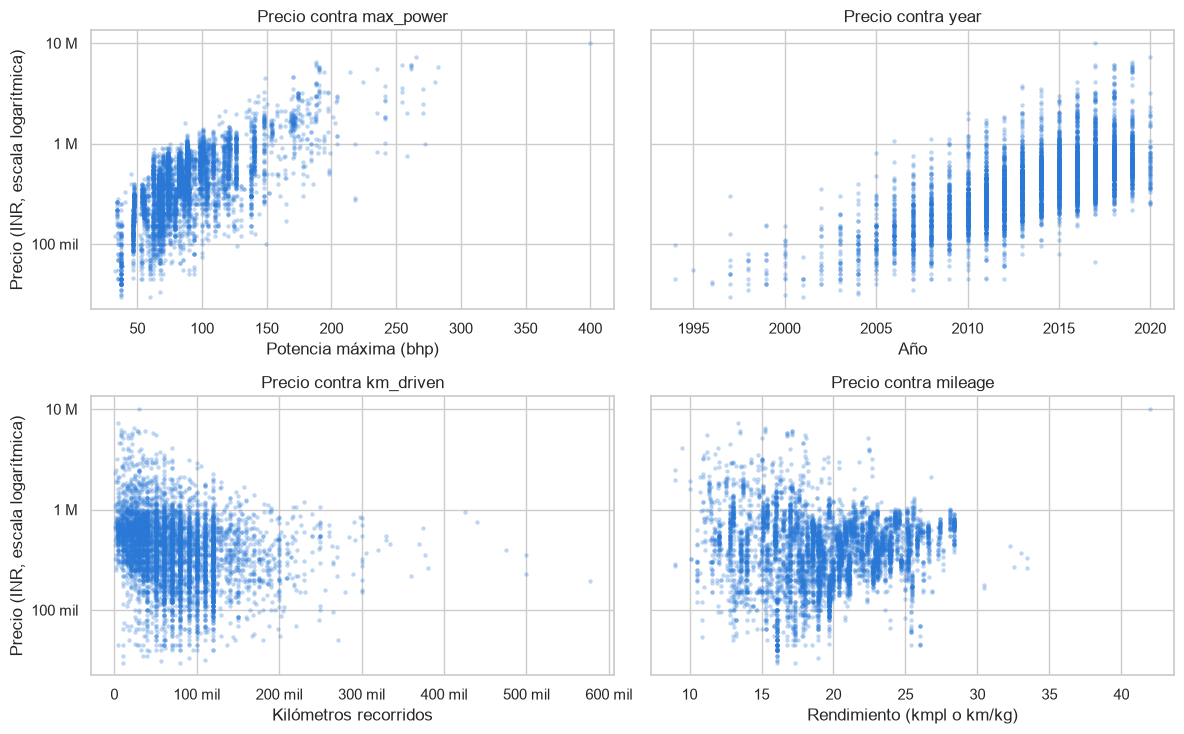

In [26]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 7.5), sharey=True)
etiquetas = {"max_power": "Potencia máxima (bhp)", "year": "Año", "km_driven": "Kilómetros recorridos",
             "mileage": "Rendimiento (kmpl o km/kg)"}

for eje, (col, etiqueta) in zip(ejes.ravel(), etiquetas.items()):
    # Puntos pequeños y transparentes para que se vea dónde se concentran los autos
    sns.scatterplot(data=df, x=col, y="selling_price", s=10, alpha=0.3, color=COLOR, linewidth=0, ax=eje)
    eje.set_yscale("log")
    eje.yaxis.set_major_formatter(FuncFormatter(formato_miles))
    eje.set(title=f"Precio contra {col}", xlabel=etiqueta, ylabel="")
for eje in ejes[:, 0]:
    eje.set_ylabel("Precio (INR, escala logarítmica)")   # el eje vertical es compartido
ejes[1, 0].xaxis.set_major_formatter(FuncFormatter(formato_miles))

plt.tight_layout()
plt.show()

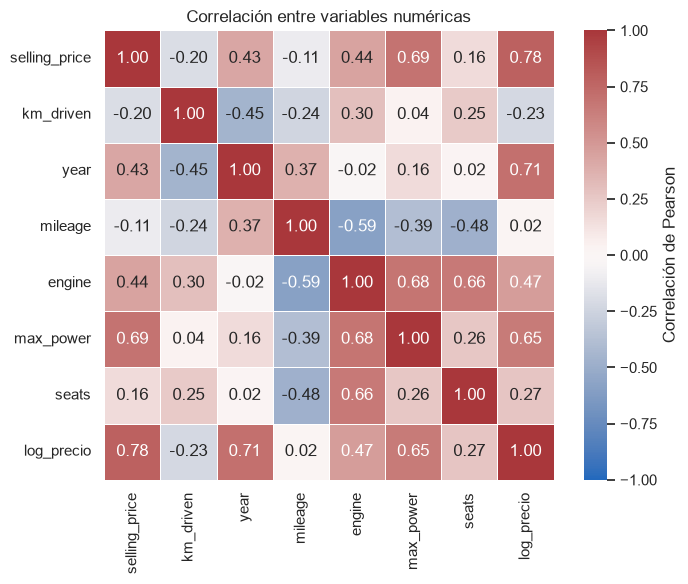

In [27]:
# Correlación de Pearson entre las variables numéricas; se agrega log(precio) para compararlo con el precio
correlacion = df[numericas].assign(log_precio=np.log(df["selling_price"])).corr()

plt.figure(figsize=(7.5, 6))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={"label": "Correlación de Pearson"})
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

**Lectura.**
- **Potencia** es la variable más relacionada con el precio (0.69). Le siguen la cilindrada (0.44) y el año (0.43).
- **El año se relaciona mucho más con el logaritmo del precio (0.71) que con el precio (0.43).** Es consistente con que cada año de antigüedad le quite al auto un porcentaje de su valor, no una cantidad fija. Es el segundo argumento para modelar el logaritmo.
- **Kilometraje** tiene la relación negativa esperada, pero débil (-0.20), y se mezcla con el año: los autos más viejos tienen más kilómetros (-0.45).
- **Colinealidad:** `engine` se relaciona con `max_power` (0.68) y con `seats` (0.66), y `mileage` con `engine` (-0.59). No impide predecir, pero vuelve poco confiables los coeficientes individuales de un modelo lineal.

## Siguiente paso

Las decisiones de limpieza de este notebook están implementadas en `semana_3_refactored_code/dataset.py`. El modelo se entrena con `semana_3_refactored_code/modeling/train.py`, que registra cada corrida en MLflow.
